# VAE-HRP: Paridad de Riesgo Jerárquica con Aprendizaje de Variedad mediante Autoencoder Variacional
## Marco de Optimización de Portafolio Walk-Forward con Ventana Expansiva

**Objetivo de investigación:** Este cuaderno implementa un *Autoencoder Variacional* (VAE) para el aprendizaje de variedad no lineal y *Hierarchical Risk Parity* (HRP) para la asignación de capital con conciencia topológica, dentro de un protocolo walk-forward causalmente disciplinado con rebalanceo trimestral. El VAE actúa como un modelo factorial no lineal de variables latentes estocásticas: comprime los retornos de los $n$ activos en una distribución de probabilidad conjunta de $k \ll n$ dimensiones, capturando el riesgo sistemático compartido y filtrando el ruido idiosincrático de cada activo. La matriz de covarianza reconstruida a partir de esta representación latente alimenta tanto los optimizadores de varianza mínima como el árbol de clústeres jerárquico de HRP.

### Universo de Inversión
Acciones pertenecientes al índice **MSCI NUAM** (mercados integrados de Chile, Colombia y Perú). Se emplean precios diarios de cierre; los activos con valores faltantes en cualquier parte del período de estudio son eliminados antes del cálculo de retornos.

### Cinco Portafolios Competidores

| Etiqueta | Estimador de Covarianza | Método de Asignación |
|----------|------------------------|----------------------|
| **A. VAE Mínima Varianza** | VAE reconstruida (ensemble de 20 modelos + MC) | Mínima Varianza (solo largo) |
| **B. VAE-HRP** | VAE reconstruida (ensemble de 20 modelos + MC) | Paridad de Riesgo Jerárquica |
| **C. Mínima Varianza Clásica** | Empírica (ventana rodante de 252 días) | Mínima Varianza (solo largo) |
| **D. HRP Clásico** | Empírica (ventana rodante de 252 días) | Paridad de Riesgo Jerárquica |
| **E. Equiponderado** | — | $1/N$ |

### Métricas de Evaluación (todas fuera de muestra)

| Métrica | Definición |
|---------|------------|
| **SD** | Desviación estándar anualizada del portafolio |
| **SR** | Sharpe Ratio anualizado (retorno anualizado menos tasa libre de riesgo de 4.62%, dividido entre SD anualizada) |
| **TOR** | Retorno total acumulado en el período OOS |
| **MD** | Máximo Drawdown (mayor caída desde pico hasta valle) |
| **Turnover** | Cambio absoluto medio en pesos $\sum_i |w_{i,t} - w_{i,t-1}|$ entre rebalanceos trimestrales consecutivos |
| **ENA** | Número Efectivo de Activos $= 1/\sum_i w_i^2$, promediado sobre todos los trimestres |

---

## 0. Configuración del Entorno e Importaciones

Se instalan las dependencias necesarias y se importan todas las librerías utilizadas en el marco. La celda de instalación solo necesita ejecutarse una vez por entorno.

**Dependencias principales:**
- `torch` — arquitectura del VAE, entrenamiento y muestreo Monte Carlo en GPU/CPU.
- `optuna` — búsqueda bayesiana de hiperparámetros con poda (*MedianPruner*).
- `scipy` / `scikit-learn` — agrupamiento jerárquico, optimización de portafolio y covarianza gráfica.
- `pandas` / `numpy` — manipulación de datos y cálculo numérico.
- `seaborn` / `matplotlib` — visualizaciones de resultados.

In [4]:
pip install optuna torch scipy scikit-learn seaborn tqdm openpyxl

Note: you may need to restart the kernel to use updated packages.


In [5]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import scipy
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform
from scipy.optimize import minimize as sp_minimize
from sklearn.covariance import GraphicalLassoCV
import optuna
from tqdm.notebook import tqdm
from scipy.spatial.distance import pdist

optuna.logging.set_verbosity(optuna.logging.WARNING)
torch.set_grad_enabled(True)

print(f'PyTorch  : {torch.__version__}')
print(f'Optuna   : {optuna.__version__}')
print('All imports successful.')


PyTorch  : 2.10.0+cu128
Optuna   : 4.8.0
All imports successful.


## 1. Carga de Datos y Cálculo de Retornos Logarítmicos

### 1.1 Datos de Precios Brutos
Se cargan los precios diarios de cierre de las acciones del índice MSCI NUAM desde el repositorio público del proyecto. El índice de fechas se convierte a `datetime` para asegurar operaciones de resampling y slicing temporal correctas.

### 1.2 Cálculo de Retornos Logarítmicos e Imputación de Datos Faltantes

Los retornos logarítmicos $r_t = \ln(P_t / P_{t-1})$ se prefieren sobre los aritméticos por su **aditividad temporal** y su mayor aproximación a la normalidad en ventanas de tiempo cortas.

**Estrategia de datos faltantes:** Los activos con valores faltantes (`NaN`) en cualquier punto de la serie de precios son eliminados antes del cálculo de retornos, ya que su presencia crónica indica iliquidez extrema que impide la construcción de ventanas deslizantes completas. Los `NaN` restantes dentro de las series, originados por trading no sincrónico entre mercados (Chile, Colombia y Perú operan en zonas horarias y calendarios distintos), son imputados con el método *forward-fill* únicamente. El *backward-fill* se excluye para preservar la **causalidad estricta**: ninguna observación futura puede influir sobre valores pasados del retorno.

In [6]:
DATA_PATH = 'https://raw.githubusercontent.com/JDELGADO2607/VAE-HRP/9f700c7b66784b2bfa29b7399bdfa32950bb712d/NUAM_CleanData%20(1).xlsx'

data = pd.read_excel(DATA_PATH, index_col='Dates')
data.index = pd.to_datetime(data.index)

nan_columns = data.columns[data.isna().any()].tolist()
print(f'Columns with NaNs (dropped): {nan_columns}')

returns_df = data.drop(columns=nan_columns)
log_returns = np.log(returns_df / returns_df.shift(1))
log_returns = log_returns.dropna(how='all')
log_returns = log_returns.fillna(method='ffill')   # forward-fill only
returns_df  = log_returns

print(f'returns_df shape : {returns_df.shape}')
print(f'Remaining NaNs   : {returns_df.isna().sum().sum()}')
print(f'Date range       : {returns_df.index[0].date()} → {returns_df.index[-1].date()}')
returns_df.tail(3)

Columns with NaNs (dropped): ['PEI CB EQUITY', 'NUAM CI EQUITY', 'IPCHBC1 PE Equity']
returns_df shape : (1771, 53)
Remaining NaNs   : 0
Date range       : 2019-07-01 → 2026-04-13


,BAP PE Equity,SCCO PE EQUITY,CHILE CI EQUITY,SQM/B CI EQUITY,PFCIBEST CB EQUITY,CENCOSUD CI EQUITY,BSAN CI EQUITY,LTM CI EQUITY,BCI CI EQUITY,CIBEST CB EQUITY,...,IAM CI EQUITY,ILC CI EQUITY,CAP CI EQUITY,CORFICOL CB EQUITY,SALFACOR CI EQUITY,FORUS CI EQUITY,SONDA CI EQUITY,OROB CI EQUITY,VOLCABC1 PE EQUITY,BICE CI EQUITY
Dates,,,,,,,,,,,,,,,,,,,,,
2026-04-09,0.006537,0.023184,0.011638,-0.017940,-0.009968,0.007843,0.006431,0.009291,0.024693,0.005131,...,-0.007770,0.000000,-0.022489,0.011991,-0.000075,0.000000,-0.003377,0.012647,0.014389,0.001848
2026-04-10,-0.011396,0.002702,0.005855,0.005289,-0.006207,0.025835,0.006645,0.001260,0.017808,0.011563,...,-0.007135,0.007220,-0.000734,-0.004779,-0.013272,-0.004272,0.017661,0.021315,0.000000,0.036795
2026-04-13,0.024623,0.031200,-0.005506,0.057309,0.026910,-0.023884,0.000764,-0.009703,-0.005012,0.013929,...,0.002123,-0.026733,0.019630,0.000000,-0.014605,-0.016607,-0.006206,0.026876,-0.014389,0.031679


## 2. Pipeline de Preprocesamiento Causal

Todas las operaciones de preprocesamiento se aplican dentro de ventanas deslizantes de $S = 60$ días de negociación. **Ningún estadístico global entra al flujo de preprocesamiento en ninguna etapa**, lo que garantiza la ausencia de sesgo de anticipación (*look-ahead bias*).

### Paso 1 — Winsorización MAD (Ec. 17)

$$r^{\text{clip}}_{t,i} = \text{clip}\!\left(r_{t,i},\; \tilde{r}_i \pm 5 \cdot \text{MAD}_i\right)$$

Para cada activo $i$ dentro de la ventana actual, se calculan la mediana $\tilde{r}_i$ y la Mediana de la Desviación Absoluta $\text{MAD}_i = \text{mediana}(|r_{t,i} - \tilde{r}_i|)$ con un multiplicador de 5. Esto limita los valores atípicos extremos derivados de episodios de iliquidez, sorpresas en resultados y perturbaciones macroeconómicas, **sin descartar la dirección del retorno**. Se prefiere la winsorización MAD al ajuste por z-score porque tanto la mediana como la MAD son estimadores robustos, no afectados por las observaciones extremas que están diseñadas para eliminar.

### Paso 2 — Estandarización (Ec. 18)

Después de la winsorización, cada serie de retornos dentro de la ventana se normaliza a **media cero y varianza unitaria** usando estadísticos calculados exclusivamente dentro de la ventana actual:

$$\tilde{r}_{t,i} = \frac{r^{\text{clip}}_{t,i} - \hat{\mu}_i}{\hat{\sigma}_i + \varepsilon}, \quad \varepsilon = 10^{-8}$$

El piso numérico $\varepsilon$ previene la división por cero en activos sin movimiento de precios durante la ventana.

> **Diseño causal:** Los estadísticos de winsorización (mediana y MAD) se estiman exclusivamente sobre las ventanas de entrenamiento y se aplican sin reajuste a las ventanas de validación, eliminando cualquier filtración de información futura. La estandarización posterior se realiza de forma autocontenida dentro de cada ventana individual.

In [7]:
S          = 60
NUM_ASSETS = returns_df.shape[1]
BATCH_SIZE = 32

print(f'Window length : {S} days')
print(f'Asset universe: {NUM_ASSETS} assets')


def preprocessing_input_returns(log_returns: torch.Tensor) -> torch.Tensor:
    median              = torch.quantile(log_returns, 0.5, dim=-2, keepdim=True)
    absolute_deviations = torch.abs(log_returns - median)
    mad                 = torch.quantile(absolute_deviations, 0.5, dim=-2, keepdim=True)
    mad_floored = torch.clamp(mad, min=1e-8)
    clipped     = torch.max(
                      torch.min(log_returns, median + 5 * mad_floored),
                      median - 5 * mad_floored
                  )
    mean = torch.mean(clipped, dim=-2, keepdim=True)
    std  = torch.std(clipped,  dim=-2, keepdim=True)
    return (clipped - mean) / torch.clamp(std, min=1e-8)

Window length : 60 days
Asset universe: 53 assets


## 3. Arquitectura del Modelo: Autoencoder Variacional Transversal (Cross-Sectional VAE)

El modelo implementa un **Autoencoder Variacional** (VAE) con operación transversal sobre el universo completo de activos. A diferencia de un autoencoder determinista, el encoder no produce un código latente fijo sino los parámetros $\mu$ y $\log\sigma^2$ de una distribución gaussiana multivariada de $k$ dimensiones latentes:

$$\mu, \sigma^2 = E_\phi(X), \quad Z \sim \mathcal{N}(\mu, \sigma^2)$$

El decoder reconstruye los $n$ retornos originales a partir de muestras estocásticas del espacio latente:

$$\hat{X} = D_\theta(Z)$$

Esta compresión obliga al modelo a funcionar como un **modelo factorial no lineal de variables latentes estocásticas**: al mapear $n$ activos en $k \ll n$ factores latentes, la red captura únicamente los movimientos conjuntos estadísticamente robustos (riesgo sistemático) y suprime el ruido idiosincrático de cada activo.

**Mecanismo de eliminación de ruido:** El dropout aplicado a la entrada corrompe aleatoriamente el retorno de cualquier activo con probabilidad $p_{\text{drop}}$ antes de ingresar al encoder. El decoder debe entonces reconstruir el vector completo a partir de una observación parcialmente corrupta, lo que fuerza al modelo a aprender las dependencias cruzadas entre activos en lugar de memorizar observaciones individuales. Esto es equivalente al proceso de corrupción de datos formalizado por Vincent et al. (2008).

**Arquitectura fija durante la búsqueda de hiperparámetros:**
- Encoder: capa oculta de 32 unidades con activación `Tanh` → capas separadas `fc_mu` y `fc_log_var` hacia el espacio latente de $k = 8$ dimensiones.
- Decoder: proyección lineal de $k = 8$ dimensiones → 32 unidades con `Tanh` → $n$ retornos reconstruidos (sin activación final, para permitir cualquier rango de valores en el espacio estandarizado).

**Truco de reparametrización:** Durante el entrenamiento, $Z = \mu + \sigma \odot \varepsilon$, $\varepsilon \sim \mathcal{N}(0, I_k)$, permitiendo la retropropagación a través de la operación de muestreo. En evaluación, se usa directamente $Z = \mu$ (modo determinista).

In [8]:
class CrossSectionalVAE(nn.Module):
    def __init__(self, num_assets: int = 53,
                 latent_dim: int = 16,
                 dropout_rate: float = 0.15):
        super().__init__()
        self.latent_dim = latent_dim
        self.dropout    = nn.Dropout(p=dropout_rate)

        self.encoder_hidden = nn.Sequential(
            nn.Linear(num_assets, 32), nn.Tanh(),
        )
        self.fc_mu      = nn.Linear(32, latent_dim)
        self.fc_log_var = nn.Linear(32, latent_dim)

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 32), nn.Tanh(),
            nn.Linear(32, num_assets),
        )

    def encode(self, x: torch.Tensor):
        self.to(device)
        x = x.to(device)
        h = self.encoder_hidden(self.dropout(x))
        return self.fc_mu(h), self.fc_log_var(h)

    def reparameterize(self, mu: torch.Tensor, log_var: torch.Tensor) -> torch.Tensor:
        if self.training:
            std = torch.exp(0.5 * log_var)
            eps = torch.randn_like(std)
            return mu + std * eps
        return mu

    def decode(self, z: torch.Tensor) -> torch.Tensor:
        return self.decoder(z)

    def forward(self, x: torch.Tensor):
        mu, log_var = self.encode(x)
        z           = self.reparameterize(mu, log_var)
        recon       = self.decode(z)
        return recon, mu, log_var


## 4. Bucle de Entrenamiento con Parada Temprana y Poda de Optuna

El VAE se entrena minimizando el **negativo del ELBO** (Límite Inferior de la Evidencia), que descompone la pérdida en dos términos:

$$\mathcal{L}(\phi, \theta) = \underbrace{\mathbb{E}_{q_\phi}\!\left[\frac{1}{T \cdot p}\sum_{t,i}(\hat{r}_{t,i} - r^{\text{target}}_{t,i})^2\right]}_{\text{Error de reconstrucción (MSE)}} + \beta \cdot \underbrace{\text{KL}\!\left[q_\phi(Z|X) \,\|\, \mathcal{N}(0, I_k)\right]}_{\text{Regularización KL}}$$

El término KL tiene una forma cerrada cuando ambas distribuciones son gaussianas:

$$\text{KL} = -\frac{1}{2}\sum_{j=1}^{k}\left(1 + \log\sigma_j^2 - \mu_j^2 - \sigma_j^2\right)$$

El hiperparámetro $\beta$ controla el balance entre fidelidad de reconstrucción y regularización del espacio latente; es uno de los parámetros optimizados por Optuna en cada fold.

**Optimizador:** Adam con `weight_decay` para regularización L2 adicional.

**Parada temprana:** Se monitorea la pérdida de validación (MSE + KL) y se restaura el mejor estado del modelo si no hay mejora durante `patience` épocas consecutivas.

**Poda de Optuna:** La integración con `trial.report()` y `trial.should_prune()` permite al `MedianPruner` terminar anticipadamente ensayos cuya pérdida de validación excede la mediana de los ensayos previos en la misma época, mejorando la eficiencia computacional de la búsqueda.

> **Consistencia de la función objetivo:** La pérdida de validación utiliza **MSE** (igual que el entrenamiento). Una versión anterior usaba MAE en validación, lo que generaba objetivos desalineados entre el bucle de entrenamiento y la comparación de Optuna entre ensayos.

In [9]:
# FIX 6: Validation reconstruction loss now uses MSE (consistent with training).
# Previously the val loop used MAE while training used MSE, causing misaligned
# early-stopping and Optuna objectives across trials.
# NOTE: circular_block_bootstrap removed (Finding 4 — sampled from full window
#       including the validation tail, risking augmentation bleed if activated).

def train_vae(model, train_loader, val_loader,
              epochs=50, lr=1e-3, weight_decay=1e-5,
              beta=1e-3, patience=5, trial=None):
    model     = model.to(device)
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    best_val          = float('inf')
    best_state        = None
    epochs_no_improve = 0

    for epoch in range(epochs):
        model.train()
        for bx, by, bw in train_loader:
            bx, by, bw = bx.to(device), by.to(device), bw.to(device)
            optimizer.zero_grad()

            recon, mu, log_var = model(bx)

            # time-weighted MSE reconstruction loss
            recon_loss = ((recon - by) ** 2 * bw[:, None, None]).mean()

            # KL divergence: -0.5 * sum(1 + log_var - mu^2 - exp(log_var))
            kld = -0.5 * torch.mean(1 + log_var - mu.pow(2) - log_var.exp())

            loss = recon_loss + beta * kld
            loss.backward()
            optimizer.step()

        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for bx, by, bw in val_loader:
                bx, by = bx.to(device), by.to(device)
                recon, mu, log_var = model(bx)
                # FIX 6: MSE here -- same objective as the training loop
                recon_l = ((recon - by) ** 2).mean()
                kld_l   = -0.5 * torch.mean(1 + log_var - mu.pow(2) - log_var.exp())
                val_loss += (recon_l + beta * kld_l).item()
        avg_val = val_loss / len(val_loader)

        if avg_val < best_val:
            best_val          = avg_val
            best_state        = {k: v.clone() for k, v in model.state_dict().items()}
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1

        if trial is not None:
            trial.report(float(avg_val), epoch)
            if trial.should_prune():
                raise optuna.exceptions.TrialPruned()

        if epochs_no_improve >= patience:
            break

    if best_state is not None:
        model.load_state_dict(best_state)
    return best_val


## 5. Funciones Auxiliares por Fold

Esta sección implementa las tres funciones que operan dentro de cada fold del walk-forward:

### `_fit_preprocess` — Ajuste de estadísticos de preprocesamiento
Calcula la mediana y MAD globales a partir de **todas las ventanas de entrenamiento** (aplanadas a $[N_{\text{tr}} \cdot S, A]$) y las devuelve con forma $[1, 1, A]$ para broadcasting libre sobre cualquier cantidad de ventanas en la etapa de aplicación.

### `_apply_preprocess` — Aplicación sin reajuste
Aplica los estadísticos ya ajustados (mediana y MAD del entrenamiento) a cualquier conjunto de ventanas, ya sea entrenamiento o validación. La estandarización posterior (media cero, varianza unitaria) se realiza de forma autocontenida dentro de cada ventana individual. **No se estiman nuevos estadísticos**, garantizando que las ventanas de validación no contaminen el pipeline con información del futuro.

### `build_loaders` — Construcción de DataLoaders
Construye las ventanas deslizantes $[N, S, A]$, realiza la división cronológica (85% entrenamiento / 15% validación), aplica el preprocesamiento causal descrito arriba, y genera los `DataLoader` de PyTorch. Las ventanas de entrenamiento se ponderan exponencialmente con factor $\gamma$ (ventanas más antiguas reciben menor peso), mientras que el DataLoader de validación preserva el orden temporal.

### `reconstruct_returns` — Reconstrucción de retornos
Procesa la serie completa de retornos del fold generando ventanas deslizantes sin *zero-padding*, aplica el escalamiento robusto per-ventana, y alimenta únicamente el **último paso temporal** de cada ventana $X_{\text{norm}}[:, -1, :]$ (forma $[T, A]$) al encoder. Esto es correcto porque el VAE es una operación transversal (*cross-sectional*): procesa un vector de $n$ activos en un instante, no una secuencia. La salida se transforma inversamente al espacio de retornos usando la media y desviación estándar del último paso temporal de cada ventana.

> **Ausencia de zero-padding:** En versiones anteriores se anteponían $S-1$ filas de ceros para alinear índices, corrompiendo los estadísticos MAD/media/std de las primeras ventanas con ceros sintéticos no presentes en el entrenamiento. Las ventanas válidas comienzan ahora en `df.index[S-1]` sin artefactos de relleno.

In [10]:
import torch
from torch.utils.data import TensorDataset, DataLoader

# ---- FIX 1: Preprocessing split into fit and transform steps -----------
# Previously build_loaders called fit_preprocessing_returns() and
# transform_preprocessing_returns() which did not exist in the notebook.
# Implemented here: statistics are computed from training windows only and
# applied (without refitting) to validation windows.

def _fit_preprocess(windows: torch.Tensor):
    """Derive MAD-winsorization statistics from training windows only.
    Args:
        windows: [N, S, A] tensor -- training split only.
    Returns:
        median: [1, 1, A], mad: [1, 1, A] -- global stats over all training
        windows, shaped for broadcasting onto any window count at apply time.
    """
    # Flatten to [N*S, A] so quantile runs over every training observation
    # per asset, then restore to [1, 1, A] for broadcast compatibility.
    N, S, A  = windows.shape
    flat     = windows.reshape(N * S, A)           # [N*S, A]
    median   = torch.quantile(flat, 0.5, dim=0)    # [A]
    abs_dev  = torch.abs(flat - median.unsqueeze(0))
    mad      = torch.quantile(abs_dev, 0.5, dim=0) # [A]
    # Reshape to [1, 1, A] so they broadcast freely over [*, S, A]
    median = median.unsqueeze(0).unsqueeze(0)       # [1, 1, A]
    mad    = mad.unsqueeze(0).unsqueeze(0)          # [1, 1, A]
    return median, torch.clamp(mad, min=1e-8)


def _apply_preprocess(windows: torch.Tensor,
                       median: torch.Tensor,
                       mad:    torch.Tensor) -> torch.Tensor:
    """Apply pre-fitted statistics to any window set (train or val).
    Winsorizes at +/-5 MAD, then z-scores using within-window mean/std.
    No new statistics are estimated -- only the supplied median/mad are used.
    """
    clipped = torch.max(
        torch.min(windows, median + 5 * mad),
        median - 5 * mad
    )
    mean = torch.mean(clipped, dim=-2, keepdim=True)
    std  = torch.std(clipped,  dim=-2, keepdim=True)
    return (clipped - mean) / torch.clamp(std, min=1e-8)


def build_loaders(df, S, batch_size=32, val_frac=0.15, gamma: float = 1.0):
    raw      = torch.tensor(df.values, dtype=torch.float32)
    raw_wins = raw.unfold(0, S, 1).transpose(1, 2)          # [N, S, A]

    N     = raw_wins.shape[0]
    n_val = max(1, int(N * val_frac))
    n_tr  = N - n_val

    # 1. Chronological split BEFORE any preprocessing
    train_raw = raw_wins[:n_tr]
    val_raw   = raw_wins[n_tr:]

    # 2. Fit statistics on training windows only (FIX 1)
    median_tr, mad_tr = _fit_preprocess(train_raw)

    # 3. Apply train-derived statistics to both splits -- no val leakage
    tensor_X_train = _apply_preprocess(train_raw, median_tr, mad_tr)
    tensor_X_val   = _apply_preprocess(val_raw,   median_tr, mad_tr)

    # 4. Reconstruction targets
    tensor_y_train = tensor_X_train.clone()
    tensor_y_val   = tensor_X_val.clone()

    # Chronological decay weights (older windows down-weighted)
    if gamma < 1.0:
        exponents = torch.arange(n_tr - 1, -1, -1, dtype=torch.float32)
        w_train   = gamma ** exponents
        w_train   = (w_train / w_train.sum() * n_tr)
    else:
        w_train = torch.ones(n_tr)

    train_ds = TensorDataset(tensor_X_train, tensor_y_train, w_train)
    val_ds   = TensorDataset(tensor_X_val,   tensor_y_val,   torch.ones(n_val))

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
    val_loader   = DataLoader(val_ds,   batch_size=batch_size, shuffle=False)

    tensor_X_full = torch.cat([tensor_X_train, tensor_X_val], dim=0)
    return train_loader, val_loader, tensor_X_full, raw_wins


# ---- FIX 2: reconstruct_returns -- remove zero-padding -----------------
# Previously S-1 zero rows were prepended, corrupting the MAD/mean/std
# statistics of early windows with synthetic zeros not present in training.
# Valid windows now start at df.index[S-1] with no padding artefacts.

def reconstruct_returns(model, df, S):
    clean = df.fillna(method='ffill')
    raw   = torch.tensor(clean.values, dtype=torch.float32)

    # No zero-padding: first valid window covers df.iloc[0:S]
    wins  = raw.unfold(0, S, 1).transpose(1, 2)   # [T-S+1, S, A]

    # Per-window robust scaling (self-contained, no cross-window leakage)
    median  = torch.quantile(wins, 0.5, dim=-2, keepdim=True)
    abs_dev = torch.abs(wins - median)
    mad_f   = torch.clamp(
        torch.quantile(abs_dev, 0.5, dim=-2, keepdim=True), min=1e-8
    )
    clipped = torch.max(torch.min(wins, median + 5 * mad_f), median - 5 * mad_f)
    w_means = torch.mean(clipped, dim=-2, keepdim=True)
    w_stds  = torch.std(clipped,  dim=-2, keepdim=True).clamp(min=1e-8)
    X_norm  = ((clipped - w_means) / w_stds).to(device)

    model.eval()
    model.to(device)
    with torch.no_grad():
        # FIX 3 (applied here too): encoder is cross-sectional.
        # Feed only the last time-step [T-S+1, A], not the full 3-D tensor.
        X_last        = X_norm[:, -1, :]          # [T-S+1, A]
        recon_z, _, _ = model(X_last)              # [T-S+1, A]

    recon = recon_z.cpu() * w_stds[:, -1, :] + w_means[:, -1, :]

    valid_index = df.index[S - 1:]                # no padding artefacts
    return pd.DataFrame(recon.numpy(), index=valid_index, columns=df.columns)


## 6. Objetivos de Optuna

### 6.1 Objetivo de Hiperparámetros del VAE

La función objetivo para la búsqueda bayesiana devuelve directamente la **pérdida de validación** (MSE de reconstrucción + $\beta \cdot$KL), que Optuna minimiza a través de 15 ensayos por fold usando el estimador TPE (*Tree-structured Parzen Estimator*).

El espacio de búsqueda abarca cuatro hiperparámetros continuos:

| Hiperparámetro | Espacio de búsqueda | Tipo |
|----------------|--------------------|---------|
| Tasa de aprendizaje (`lr`) | $[10^{-4},\, 10^{-2}]$ | Log-uniforme |
| Decaimiento de pesos (`weight_decay`) | $[10^{-6},\, 10^{-3}]$ | Log-uniforme |
| Peso KL ($\beta$) | $[10^{-5},\, 10^{-2}]$ | Log-uniforme |
| Tasa de dropout ($p_{\text{drop}}$) | $[0.05,\, 0.40]$ | Uniforme |

La arquitectura del VAE permanece fija durante la búsqueda: una capa oculta de 32 unidades con activación `Tanh` y dimensión latente $k = 8$.

### 6.2 Funciones del Pipeline HRP

Se implementan las cuatro funciones que componen el pipeline de Paridad de Riesgo Jerárquica:

- **`get_quasi_diag`**: A partir de la matriz de enlace (*linkage*) jerárquico, reordena los activos en el orden cuasi-diagonal que minimiza las distancias entre activos adyacentes en el árbol.
- **`getIVP`**: Calcula los pesos de paridad de varianza inversa ($w_i \propto 1/\sigma_i^2$) para un subconjunto de activos, usados en la bisección recursiva.
- **`getClusterVar`**: Calcula la varianza del portafolio IVP para un clúster dado, usada como criterio de asignación en la bisección.
- **`getRecBipart`**: Implementa la bisección recursiva de López de Prado (2016): divide sucesivamente los clústeres en mitades y asigna capital proporcionalmente al inverso de la varianza de cada mitad. Si la suma de varianzas de ambas mitades es degenerada ($< 10^{-10}$), se aplica un reparto igualitario $\alpha = 0.5$ para evitar divisiones por cero.
- **`build_distance_matrix`**: Convierte la matriz de covarianza en una matriz de distancias de correlación: $d_{ij} = \sqrt{\tfrac{1}{2}(1 - \hat{\rho}_{ij})}$ (distancia estándar) o $d_{ij} = \sqrt{1 - |\hat{\rho}_{ij}|}$ (distancia de correlación absoluta).
- **`hrp_empirical`**: Construye el árbol jerárquico sobre la matriz de distancias de la covarianza empírica y aplica la bisección recursiva.
- **`hrp_latent`**: Construye el árbol jerárquico usando distancias **euclidianas sobre las representaciones latentes** $Z^\top$ (dimensión $[k, T]$), capturando la topología del espacio de factores del VAE en lugar de las correlaciones de retornos directas.

In [11]:
def make_vae_objective(train_loader, val_loader, num_assets):
    def objective(trial):
        lr           = trial.suggest_float('lr',           1e-4, 1e-2,  log=True)
        weight_decay = trial.suggest_float('weight_decay', 1e-6, 1e-3,  log=True)
        beta         = trial.suggest_float('beta',         1e-5, 1e-2,  log=True)
        dropout_rate = trial.suggest_float('dropout_rate', 0.05, 0.40)

        model = CrossSectionalVAE(num_assets=num_assets,
                                  latent_dim=8,
                                  dropout_rate=dropout_rate)
        val_loss = train_vae(model, train_loader, val_loader,
                             epochs=50, lr=lr, weight_decay=weight_decay,
                             beta=beta, patience=5, trial=trial)
        return val_loss
    return objective

from scipy.spatial.distance import pdist, squareform


def get_quasi_diag(link):
    link      = link.astype(int)
    sort_ix   = pd.Series([link[-1, 0], link[-1, 1]])
    num_items = link[-1, 3]
    while sort_ix.max() >= num_items:
        sort_ix.index = pd.RangeIndex(0, sort_ix.shape[0] * 2, 2)
        df0 = sort_ix[sort_ix >= num_items]
        i, j = df0.index, df0.values - num_items
        sort_ix[i] = link[j, 0]
        df1 = pd.Series(link[j, 1], index=i + 1)
        sort_ix = pd.concat([sort_ix, df1]).sort_index()
        sort_ix.index = pd.RangeIndex(sort_ix.shape[0])
    return sort_ix.tolist()


def getIVP(cov_matrix):
    epsilon = 1e-8
    ivp = 1.0 / (np.diag(cov_matrix.values) + epsilon)
    return ivp / ivp.sum()


def getClusterVar(cov_matrix, items):
    sub_cov = cov_matrix.loc[items, items].astype(float)

    w_ = getIVP(sub_cov).reshape(-1,1)

    return np.dot(np.dot(w_.T, sub_cov.values), w_).item()



def getRecBipart(cov_matrix, ordered_items):
    w      = pd.Series(1.0, index=ordered_items)
    cItems = [ordered_items]
    while len(cItems) > 0:
        cItems = [i[j:k] for i in cItems
                  for j, k in ((0, len(i) // 2), (len(i) // 2, len(i)))
                  if len(i) > 1]
        for i in range(0, len(cItems), 2):
            c0, c1 = cItems[i], cItems[i + 1]
            var0   = getClusterVar(cov_matrix, c0)
            var1   = getClusterVar(cov_matrix, c1)
            denom  = var0 + var1
            alpha  = 0.5 if denom < 1e-10 else 1.0 - var0 / denom
            w.loc[c0] *= alpha
            w.loc[c1] *= 1.0 - alpha
    return w


def build_distance_matrix(cov_matrix: pd.DataFrame, use_abs: bool = False) -> np.ndarray:
    vols      = np.sqrt(np.maximum(np.diag(cov_matrix.values), 1e-12))
    corr_clip = (cov_matrix.values / np.outer(vols, vols)).clip(-1.0, 1.0)
    d_corr    = (np.sqrt(np.maximum(1.0 - np.abs(corr_clip), 0.0))
                 if use_abs else
                 np.sqrt(np.maximum(0.5 * (1.0 - corr_clip), 0.0)))
    np.fill_diagonal(d_corr, 0.0)
    return d_corr


def hrp_empirical(cov_matrix: pd.DataFrame,
                  linkage_method: str = 'ward') -> pd.Series:
    d_condensed = squareform(build_distance_matrix(cov_matrix), checks=False)
    link        = linkage(d_condensed, method=linkage_method)
    sort_ix     = get_quasi_diag(link)
    ordered     = cov_matrix.columns[sort_ix].tolist()
    w           = getRecBipart(cov_matrix, ordered)
    return w / w.sum()


def hrp_latent(cov_matrix: pd.DataFrame,
               Z: np.ndarray,
               linkage_method: str = 'ward') -> pd.Series:
    d_condensed = pdist(Z.T, metric='euclidean')
    link        = linkage(d_condensed, method=linkage_method)
    sort_ix     = get_quasi_diag(link)
    ordered     = cov_matrix.columns[sort_ix].tolist()
    w           = getRecBipart(cov_matrix, ordered)
    return w / w.sum()

## 7. Utilidades de Construcción de Portafolio

### Mínima Varianza (Solo Largo, Con Restricciones)

$$\min_w\; w^\top \hat{\Sigma} w \quad \text{s.t.} \quad \mathbf{1}^\top w = 1,\; w \geq 0$$

La solución analítica para el caso sin restricción de positividad es:

$$w^* = \frac{\hat{\Sigma}^{-1}\mathbf{1}}{\mathbf{1}^\top \hat{\Sigma}^{-1}\mathbf{1}}$$

Se implementa esta forma cerrada con regularización numérica ($+10^{-10} I$) cuando la matriz es singularmente cercana a ser singular.

### Paridad de Riesgo (*Risk Parity*)

Minimiza la dispersión de las contribuciones de riesgo entre activos:

$$\min_w \sum_i \left(\frac{w_i (\hat{\Sigma} w)_i}{w^\top \hat{\Sigma} w} - \frac{1}{n}\right)^2 \quad \text{s.t.} \quad \mathbf{1}^\top w = 1,\; w \geq 0$$

La optimización se realiza con SLSQP. Esta función se incluye como utilidad alternativa; la asignación principal basada en VAE usa el pipeline HRP de la sección 6.

In [12]:
def mvp_weights_from_cov(cov: np.ndarray) -> np.ndarray:
    ones = np.ones(cov.shape[0])
    try:
        inv = np.linalg.inv(cov)
    except np.linalg.LinAlgError:
        inv = np.linalg.inv(cov + 1e-10 * np.eye(cov.shape[0]))
    w = inv @ ones
    return w / w.sum()


def mvp_weights(cov: np.ndarray) -> np.ndarray:
    return mvp_weights_from_cov(cov)


def risk_parity_weights(cov: np.ndarray) -> np.ndarray:
    n = cov.shape[0]
    cov_ = cov + 1e-10 * np.eye(n)

    def objective(w):
        port_var = float(w @ cov_ @ w)
        mrc = cov_ @ w
        rc = w * mrc / max(port_var, 1e-12)
        return float(((rc - 1.0 / n) ** 2).sum())

    constraints = [{'type': 'eq', 'fun': lambda w: w.sum() - 1.0}]
    bounds = [(0.0, 1.0)] * n
    res = sp_minimize(objective, np.ones(n) / n,
                      method='SLSQP', bounds=bounds,
                      constraints=constraints,
                      options={'ftol': 1e-10, 'maxiter': 1000})
    w = np.clip(res.x if res.success else np.ones(n) / n, 0.0, None)
    return w / w.sum()


## 8. Funciones de Métricas de Desempeño

Todas las métricas se calculan sobre la serie de retornos diarios fuera de muestra. La anualización usa 252 días hábiles de negociación.

| Métrica | Fórmula |
|---------|----------|
| **SD** | $\sigma_{\text{ann}} = \sigma_{\text{diaria}} \sqrt{252}$ |
| **SR** | $\text{SR} = (\mu_{\text{ann}} - r_f) / \sigma_{\text{ann}}$, con $r_f = 4.62\%$ |
| **TOR** | $\prod_t(1+r_t) - 1$ |
| **MD** | $\min_t \left(V_t - \max_{s \le t} V_s\right) / \max_{s \le t} V_s$ |
| **Turnover** | $\frac{1}{K-1}\sum_{k=2}^{K} \sum_i |w_{i,k} - w_{i,k-1}|$ |
| **ENA** | $1 / \sum_i w_i^2$, promediado sobre todos los rebalanceos |

El **Número Efectivo de Activos (ENA)** es el recíproco del Índice Herfindahl-Hirschman aplicado a los pesos: mide la diversificación efectiva del portafolio. Un valor de $N$ indica ponderación perfectamente uniforme; valores bajos indican concentración en pocos activos.

La función `summarise_portfolio` consolida todas las métricas en un diccionario para su posterior agregación en el DataFrame de resultados.

In [13]:
TRADING_DAYS = 252


def compute_sd(daily_returns: pd.Series) -> float:
    return float(daily_returns.std() * np.sqrt(TRADING_DAYS))


def compute_sr(daily_returns: pd.Series, risk_free_rate: float = 0.0462) -> float:
    
    ann_ret = float((1 + daily_returns).prod() ** (TRADING_DAYS / len(daily_returns)) - 1)
    
    ann_vol = compute_sd(daily_returns)

    return ((ann_ret - risk_free_rate) / ann_vol)


def compute_total_return(daily_returns: pd.Series) -> float:
    return float((1 + daily_returns).prod() - 1)


def compute_max_drawdown(daily_returns: pd.Series) -> float:
    cum  = (1 + daily_returns).cumprod()
    peak = cum.cummax()
    return float(((cum - peak) / peak).min())


def compute_turnover(weights_history: list) -> float:
    if len(weights_history) < 2:
        return np.nan
    diffs = [np.sum(np.abs(weights_history[k] - weights_history[k - 1]))
             for k in range(1, len(weights_history))]
    return float(np.mean(diffs))

def compute_ena(weights_history: list) -> float:
    """Effective Number of Assets via HHI: ENA = 1 / sum(w_i^2), averaged across rebalances."""
    enas = [1.0 / np.sum(w ** 2) for w in weights_history if np.sum(w ** 2) > 1e-12]
    return float(np.mean(enas)) if enas else np.nan

def summarise_portfolio(label: str,
                        oos_returns: pd.Series,
                        weights_history: list) -> dict:
    return {
        'Portfolio': label,
        'SD'       : compute_sd(oos_returns),
        'SR'       : compute_sr(oos_returns),
        'TOR'      : compute_total_return(oos_returns),
        'MD'       : compute_max_drawdown(oos_returns),
        'Turnover' : compute_turnover(weights_history),
    }


## 9. Fundamento Teórico: Por qué las Representaciones Latentes del VAE Mejoran HRP

### 9.1 El Problema de la Covarianza Empírica en HRP

El árbol de enlace en HRP se construye a partir de la matriz de distancias $d_{ij} = \sqrt{\tfrac{1}{2}(1 - \hat{\rho}_{ij})}$. Cuando la covarianza muestral $\hat{\Sigma}$ está contaminada por ruido idiosincrático, $\hat{\rho}_{ij}$ sobreestima la co-movilidad idiosincrática, produciendo proximidades topológicas incorrectas y una asignación de capital subóptima.

Además, cuando el número de activos $n$ se acerca o supera al número de observaciones $T$, la matriz de covarianza muestral es deficiente en rango y su inversa es numéricamente inestable (Michaud, 1989). Pequeñas perturbaciones en la covarianza estimada producen grandes cambios en el vector de pesos óptimos, generando portafolios que representan errores de estimación en lugar de la estructura de riesgo real.

### 9.2 El VAE como Modelo Factorial No Lineal

El VAE aprende a aproximar la función de puntuación (*score function*) de la distribución de los datos (Vincent et al., 2008): $f_\theta(\tilde{x}) \approx x + \sigma^2 \nabla_x \log p(x)$. Los retornos reconstruidos retienen las correlaciones de los factores macro mientras atenúan la varianza idiosincrática. Al comprimir $n$ activos en $k$ factores latentes, la red captura los movimientos conjuntos de forma robusta al ruido.

### 9.3 De la Reconstrucción VAE a la Topología HRP

La matriz de covarianza de rango completo se reconstruye bajo la **descomposición aproximada del modelo factorial** de Chamberlain & Rothschild (1983):

$$\hat{\Sigma}^{\text{FR}}_{\text{VAE}} = \hat{\Sigma}_{\text{VAE}} + \text{diag}\!\left(\hat{\Sigma}_{\text{empírica}} - \hat{\Sigma}_{\text{VAE}}\right)^+$$

donde $[\cdot]^+$ indica que los valores negativos de la diagonal se truncan a cero. Esta descomposición agrega la varianza idiosincrática individual eliminada en la compresión latente, produciendo una matriz de rango completo con inversa matemáticamente bien definida.

### 9.4 Deep Ensemble para Estabilización de la Covarianza

La estimación de la matriz de covarianza mediante un único modelo entrenado está sujeta a la varianza del proceso de optimización estocástica: distintas inicializaciones de los pesos pueden converger a mínimos locales diferentes en la superficie de pérdida no convexa del VAE. Para mitigar esta fuente de variabilidad, el marco entrena $M = 20$ modelos independientes (*Deep Ensemble*, Lakshminarayanan et al., 2017), cada uno con una semilla aleatoria distinta pero compartiendo los hiperparámetros óptimos identificados por la búsqueda bayesiana. La semilla del $m$-ésimo miembro se fija como $42 + q + m$ para garantizar reproducibilidad estricta. La estimación final es el promedio aritmético de las $M$ matrices individuales:

$$\hat{\Sigma}_{\text{VAE}} = \frac{1}{M}\sum_{m=1}^{M} \hat{\Sigma}^{\text{MC}}_{(m)}$$

### 9.5 Estimación Monte Carlo de la Covarianza

Dado que el VAE define una distribución posterior aproximada $q_\phi(Z|X)$ en lugar de un código latente determinístico, se emplea simulación de Monte Carlo para estimar la esperanza de la distribución de matrices de covarianza. Para cada fold, el encoder procesa el último paso temporal de cada ventana y devuelve $\mu$ y $\log\sigma^2$. A continuación se generan $S = 250$ muestras mediante el truco de reparametrización. Cada muestra se decodifica y la matriz de covarianza Monte Carlo se estima como:

$$\hat{\Sigma}^{\text{MC}} = \frac{1}{S}\sum_{s=1}^{S} \text{Cov}(\hat{r}^{(s)})$$

donde $\hat{r}^{(s)} \in \mathbb{R}^{T \times n}$ es la matriz de retornos reconstruidos para la muestra $s$.

## 10. Visualización de la Matriz de Covarianza Cuasi-Diagonal

La función `plot_quasi_diagonal_cov` reordena las filas y columnas de la matriz de covarianza según el orden cuasi-diagonal inducido por el árbol de enlace jerárquico HRP, y visualiza la matriz de correlación resultante como un mapa de calor.

Este gráfico permite comparar visualmente la **estructura de bloques** de la covarianza empírica frente a la covarianza reconstruida por el VAE. Una estructura de bloques más limpia indica que el VAE ha logrado aislar los factores sistemáticos, agrupando activos con co-movimiento genuino y separando aquellos cuyas correlaciones son principalmente ruido.

In [14]:
def plot_quasi_diagonal_cov(cov_matrix: pd.DataFrame,
                             linkage_method: str = 'average',
                             use_abs_corr: bool  = False,
                             title_suffix: str   = '',
                             ax=None):
    d_condensed   = squareform(build_distance_matrix(cov_matrix, use_abs=use_abs_corr),
                               checks=False)
    link          = linkage(d_condensed, method=linkage_method)
    sort_ix       = get_quasi_diag(link)
    ordered       = cov_matrix.columns[sort_ix].tolist()
    cov_reordered = cov_matrix.loc[ordered, ordered]

    show = ax is None
    if show:
        fig, ax = plt.subplots(figsize=(10, 8))

    vols           = np.sqrt(np.diag(cov_reordered.values))
    corr_reordered = cov_reordered.values / np.outer(vols, vols)
    np.fill_diagonal(corr_reordered, 1.0)

    im = ax.imshow(corr_reordered, cmap='RdBu_r', vmin=-1, vmax=1, aspect='auto')
    ax.set_title(f'Quasi-Diagonal Correlation Matrix{title_suffix}', fontsize=12)
    ax.set_xlabel('Asset (quasi-diag order)')
    ax.set_ylabel('Asset (quasi-diag order)')
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    if show:
        plt.tight_layout()
        plt.show()
    return ordered


## 11. Backtest Walk-Forward con Ventana Expansiva — Rebalanceo Trimestral

### Protocolo Walk-Forward

El protocolo walk-forward simula la secuencia de decisiones que tomaría un gestor de carteras en tiempo real. En cada iteración, todo el proceso (preprocesamiento, entrenamiento del VAE, búsqueda bayesiana de hiperparámetros y construcción de ponderaciones) se ejecuta exclusivamente a partir de información disponible antes del inicio del período de prueba.

Sea $\{y_i\}_{i=1}^{T}$ el conjunto de trimestres calendario disponibles. Para cada fold $k$ con historia mínima de $k_{\min} = 5$ trimestres:

$$\text{Entrenamiento}_k = \{r_t : t < y_k\}, \qquad \text{Prueba}_k = \{r_t : y_k \leq t < y_{k+1}\}$$

El conjunto de entrenamiento es **expansivo**: acumula todas las observaciones disponibles hasta el trimestre en curso. El conjunto de prueba corresponde siempre al trimestre inmediatamente siguiente.

Dentro del período de entrenamiento de cada fold, el **conjunto de validación interna** se construye como el 15% más reciente de las ventanas deslizantes disponibles, en orden cronológico estricto (todas las observaciones de validación son temporalmente posteriores a todas las de entrenamiento).

### Función `get_expected_vae_covariance`

Genera la estimación Monte Carlo de la matriz de covarianza para un único miembro del ensemble:

1. Construye ventanas deslizantes de $S = 60$ días sobre la ventana de entrenamiento reciente (252 días).
2. Aplica el escalamiento robusto per-ventana.
3. Alimenta únicamente el **último paso temporal** de cada ventana ($X_{\text{norm}}[:, -1, :]$, forma $[T, A]$) al encoder para obtener $\mu$ y $\log\sigma^2$.
4. Genera $S = 250$ muestras del espacio latente mediante el truco de reparametrización.
5. Decodifica cada muestra, transforma al espacio de retornos y promedia las matrices de covarianza muestrales.

> **Corrección de indexación del encoder:** Una versión anterior pasaba el tensor completo $[T, S, A]$ al encoder y luego extraía `mu[:, -1, :]`, lo que en un tensor 2-D de salida extraía silenciosamente la *última columna de features* en lugar de la *representación del último paso temporal*, corrompiendo todas las matrices de covarianza y los pesos de portafolio derivados.

### Cinco Portafolios Evaluados Simultáneamente

| Portafolio | Ventana para Cov | Método de Pesos |
|------------|-----------------|------------------|
| A. VAE Mínima Varianza | Ensemble VAE (252d → expansiva) | Mínima Varianza |
| B. VAE-HRP | Ensemble VAE (252d → expansiva) | HRP (linkage `ward`) |
| C. Mínima Varianza Clásica | Empírica rodante 252d | Mínima Varianza |
| D. HRP Clásico | Empírica rodante 252d | HRP Empírico |
| E. Equiponderado | — | $1/N$ |

In [15]:
def get_expected_vae_covariance(model, recent_df: pd.DataFrame,
                                S: int,
                                num_samples: int = 250) -> np.ndarray:
    model.eval()
    model.to(device)

    clean   = recent_df.fillna(method='ffill')
    raw     = torch.tensor(clean.values, dtype=torch.float32)
    padding = torch.zeros(S - 1, raw.shape[1])
    padded  = torch.cat([padding, raw], dim=0)
    wins    = padded.unfold(0, S, 1).transpose(1, 2)       # [T, S, A]

    # Robust per-window scaling (same pipeline as build_loaders)
    median  = torch.quantile(wins, 0.5, dim=-2, keepdim=True)
    abs_dev = torch.abs(wins - median)
    mad     = torch.quantile(abs_dev, 0.5, dim=-2, keepdim=True)
    mad_f   = torch.clamp(mad, min=1e-8)
    clipped = torch.max(torch.min(wins, median + 5 * mad_f), median - 5 * mad_f)
    w_mean  = torch.mean(clipped, dim=-2, keepdim=True)    # [T, 1, A]
    w_std   = torch.std(clipped,  dim=-2, keepdim=True).clamp(min=1e-8)

    # Scalars needed for inverse-transform (last time-step of each window)
    w_mean_last = w_mean[:, -1, :].cpu()                   # [T, A]
    w_std_last  = w_std[:,  -1, :].cpu()                   # [T, A]

    # FIX 3: CrossSectionalVAE.encode() is a per-time-step (2-D) operation.
    # Previously encode() received the full [T, S, A] tensor; then
    # mu[:, -1, :] silently sliced the last *feature column* of the 2-D
    # output, not a time-step embedding, corrupting every covariance matrix.
    # Correct: feed only the last time-step [T, A] to the encoder.
    X_last = ((clipped - w_mean) / w_std)[:, -1, :].to(device)  # [T, A]

    cov_accum = np.zeros((recent_df.shape[1], recent_df.shape[1]))

    with torch.no_grad():
        mu, log_var = model.encode(X_last)                 # [T, latent]

        for _ in range(num_samples):
            std = torch.exp(0.5 * log_var)
            eps = torch.randn_like(std)
            z   = mu + std * eps                           # [T, latent]

            recon_z = model.decode(z).cpu()                # [T, A]  (z-score space)
            recon_r = recon_z * w_std_last + w_mean_last   # [T, A]  (return space)

            cov_accum += np.cov(recon_r.numpy().T)

    return cov_accum / num_samples


In [16]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')

Device: cuda


Total quarters in dataset : 28
First OOS quarter         : 2020-10-01 00:00:00
Ensemble size             : 20 seeds


Quarterly Walk-Forward:   0%|          | 0/22 [00:00<?, ?it/s]


Q5 | Train end: 2020-10-01 (328d) | Test: 2020-10-01→2021-01-01 (66d)
  Best val loss : 0.518547 | beta=1.22e-04 | latent_dim=8
  Ensemble complete (20 members trained)


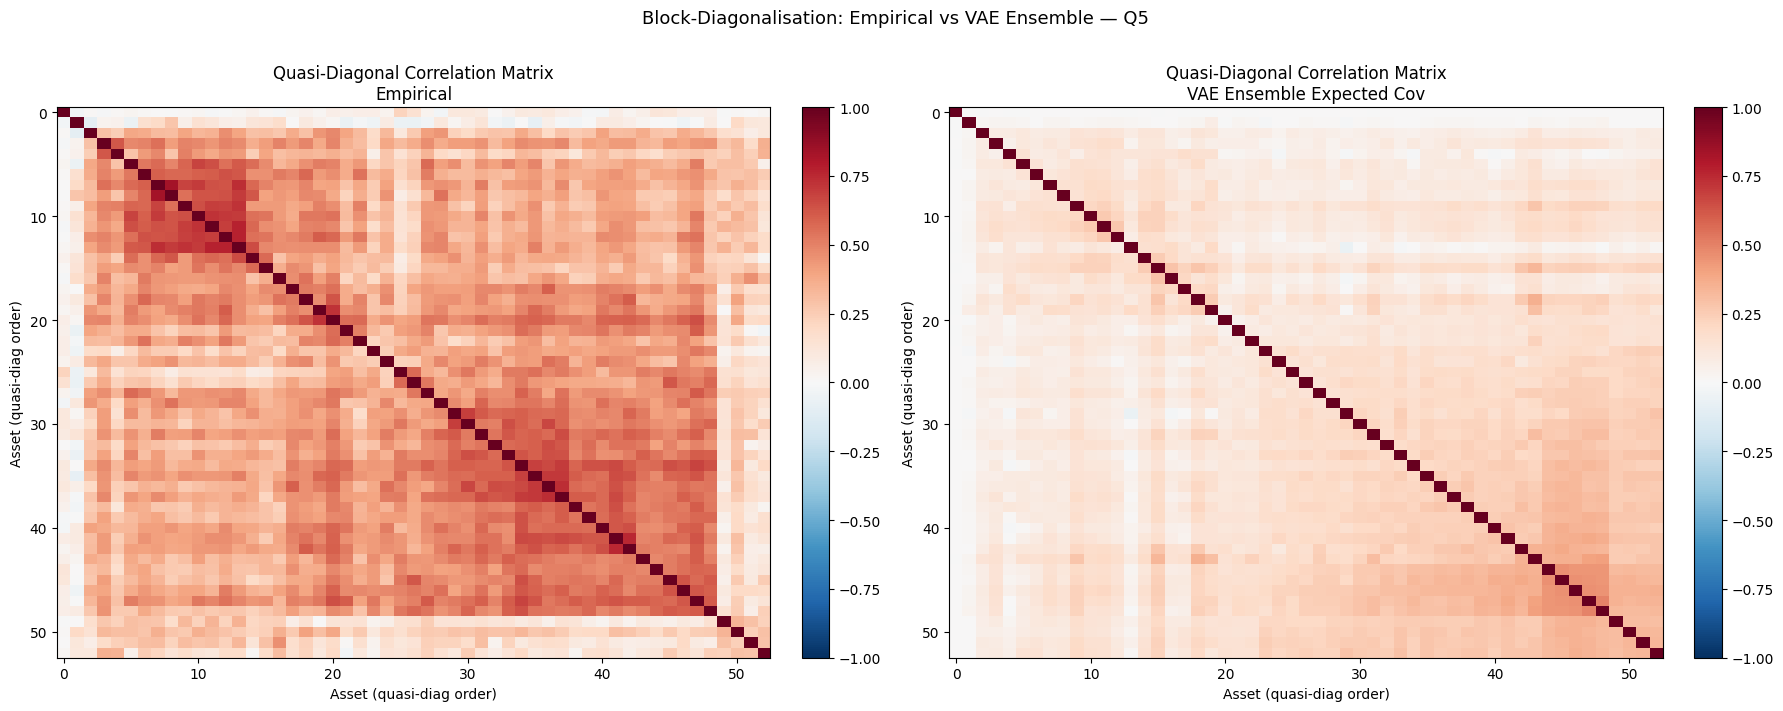

  OOS SD — MVP-Emp: 13.10%  HRP-Emp: 12.49%  DAE-MVP: 9.74%  DAE-HRP: 12.42%  EW: 15.45%

Q6 | Train end: 2021-01-01 (394d) | Test: 2021-01-01→2021-04-01 (64d)
  Best val loss : 0.558371 | beta=5.24e-04 | latent_dim=8
  Ensemble complete (20 members trained)
  OOS SD — MVP-Emp: 1.60%  HRP-Emp: 1.76%  DAE-MVP: 1.56%  DAE-HRP: 1.73%  EW: 12.54%

Q7 | Train end: 2021-04-01 (458d) | Test: 2021-04-01→2021-07-01 (65d)
  Best val loss : 0.581057 | beta=3.38e-04 | latent_dim=8
  Ensemble complete (20 members trained)
  OOS SD — MVP-Emp: 14.24%  HRP-Emp: 14.34%  DAE-MVP: 14.34%  DAE-HRP: 14.33%  EW: 20.67%

Q8 | Train end: 2021-07-01 (523d) | Test: 2021-07-01→2021-10-01 (66d)
  Best val loss : 0.523507 | beta=1.10e-04 | latent_dim=8
  Ensemble complete (20 members trained)
  OOS SD — MVP-Emp: 11.30%  HRP-Emp: 8.74%  DAE-MVP: 9.83%  DAE-HRP: 9.27%  EW: 12.09%

Q9 | Train end: 2021-10-01 (589d) | Test: 2021-10-01→2022-01-01 (66d)
  Best val loss : 0.521130 | beta=7.15e-05 | latent_dim=8
  Ensembl

In [17]:
# ════════════════════════════════════════════════════════════════════════════
# CONFIGURATION
# ════════════════════════════════════════════════════════════════════════════
S              = 60
BATCH_SIZE     = 32
DAE_TRIALS     = 15
OPT_WINDOW     = 252
TRADING_DAYS   = 252
GAMMA          = 0.995
N_ENSEMBLE     = 20
 
records = {
    'mvp_emp'  : {'returns': [], 'weights': []},
    'hrp_emp'  : {'returns': [], 'weights': []},
    'dae_only' : {'returns': [], 'weights': []},
    'dae_hrp'  : {'returns': [], 'weights': []},
    'eq_weight': {'returns': [], 'weights': []},
}
 
fold_summaries = []
 
returns_df.index = pd.to_datetime(returns_df.index)
quarters = returns_df.resample('QS').first().index
MIN_TRAIN_QUARTERS = 5
 
# FIX 5: Pruner is now instantiated inside the loop (see below).
# A single global pruner accumulates trial history across folds, allowing
# earlier OOS validation losses to bias pruning in later folds.
 
print(f'Total quarters in dataset : {len(quarters)}')
print(f'First OOS quarter         : {quarters[MIN_TRAIN_QUARTERS]}')
print(f'Ensemble size             : {N_ENSEMBLE} seeds')
 
# ════════════════════════════════════════════════════════════════════════════
# QUARTERLY WALK-FORWARD LOOP
# ════════════════════════════════════════════════════════════════════════════
for q_idx in tqdm(
    range(MIN_TRAIN_QUARTERS, len(quarters) - 1),
    desc='Quarterly Walk-Forward'
):
    train_end  = quarters[q_idx]
    test_start = quarters[q_idx]
    test_end   = quarters[q_idx + 1]
 
    train_mask = returns_df.index < test_start
    test_mask  = (returns_df.index >= test_start) & (returns_df.index < test_end)
 
    train_df = returns_df[train_mask].copy()
    test_df  = returns_df[test_mask].copy()
 
    if len(train_df) < OPT_WINDOW + S or len(test_df) == 0:
        continue
 
    NUM_ASSETS = train_df.shape[1]
    tqdm.write(f'\nQ{q_idx} | Train end: {train_end.date()} ({len(train_df)}d) | '
               f'Test: {test_start.date()}→{test_end.date()} ({len(test_df)}d)')
 
    # ── 1. Two windows: expanding for VAE, rolling for empirical baselines ──
    vae_train_raw    = train_df.copy()
    recent_train_raw = train_df.iloc[-OPT_WINDOW:]
 
    # ── 2. Build loaders: chronological split (85% train / 15% val), no bootstrap ──
    # vae_train_raw is passed directly; build_loaders handles the split internally
    # via val_frac=0.15.
    train_loader, val_loader, _, _ = build_loaders(
        vae_train_raw, S, BATCH_SIZE, val_frac=0.15, gamma=GAMMA
    )
 
    # ── 3. Vanilla Optuna search — standard TPE, no multivariate, no CMA-ES ─
    sampler     = optuna.samplers.TPESampler(seed=42 + q_idx)
    # FIX 5: fresh pruner every fold -- no cross-fold state contamination
    fold_pruner = optuna.pruners.MedianPruner(
        n_startup_trials=5, n_warmup_steps=10, interval_steps=1
    )
    vae_study = optuna.create_study(
        direction='minimize',
        sampler=sampler,
        pruner=fold_pruner,
    )
    vae_study.optimize(
        make_vae_objective(train_loader, val_loader, NUM_ASSETS),
        n_trials=DAE_TRIALS,
    )
    best_p = vae_study.best_params
    tqdm.write(f'  Best val loss : {vae_study.best_value:.6f} | '
               f'beta={best_p["beta"]:.2e} | latent_dim=8')
 
    # ── 4. 20-Seed Deep Ensemble ─────────────────────────────────────────────
    # Each seed trains a fresh model with the optimal hyperparameters found
    # above. Monte Carlo covariance matrices are collected and averaged, which
    # naturally stabilises the estimate without any ad-hoc regularisation.
    ensemble_covs = []
 
    for i in range(N_ENSEMBLE):
        # Strict per-iteration determinism
        torch.manual_seed(42 + q_idx + i)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(42 + q_idx + i)
 
        # Fresh model — same optimal hyperparameters, different random init
        member_model = CrossSectionalVAE(
            num_assets=NUM_ASSETS,
            latent_dim=8,
            dropout_rate=best_p['dropout_rate'],
        )
 
        # Standard training: pure MSE + KLD loss, early stopping
        train_vae(
            member_model,
            train_loader,
            val_loader,
            epochs=100,
            lr=best_p['lr'],
            weight_decay=best_p['weight_decay'],
            beta=best_p['beta'],
            patience=10,
        )
 
        # Monte Carlo expected covariance for this member
        member_cov = get_expected_vae_covariance(
            member_model, recent_train_raw, S, num_samples=250
        )
        ensemble_covs.append(member_cov)
 
    tqdm.write(f'  Ensemble complete ({N_ENSEMBLE} members trained)')
 
    # ── 5. Average ensemble covariances → single stable matrix ───────────────
    cov_tr_vae_mc = np.mean(ensemble_covs, axis=0)   # shape: (A, A)
 
    # ── 6. Idiosyncratic variance restoration on the averaged matrix ─────────
    cov_tr_raw    = np.cov(recent_train_raw.values.T)
    id_var        = np.clip(np.diag(np.diag(cov_tr_raw - cov_tr_vae_mc)), 0, None)
    cov_tr_vae_fr = cov_tr_vae_mc + id_var
    cov_vae_df    = pd.DataFrame(
        cov_tr_vae_fr,
        index=recent_train_raw.columns,
        columns=recent_train_raw.columns,
    )
 
    # ── 7. Portfolio — MinVar-Emp (rolling 252d empirical) ───────────────────
    w_mvp_emp = mvp_weights_from_cov(cov_tr_raw)
 
    # ── 8. Portfolio — HRP-Emp (rolling 252d empirical) ──────────────────────
    cov_raw_df  = pd.DataFrame(
        cov_tr_raw,
        index=recent_train_raw.columns,
        columns=recent_train_raw.columns,
    )
    w_hrp_emp_s = hrp_empirical(cov_raw_df)
    w_hrp_emp   = w_hrp_emp_s.reindex(recent_train_raw.columns).fillna(0.0).values
    w_hrp_emp   = w_hrp_emp / w_hrp_emp.sum()
 
    # ── 9. Portfolio — VAE-Only MVP (ensemble-averaged cov) ──────────────────
    w_dae_mvp = mvp_weights_from_cov(cov_tr_vae_fr)
 
    # ── 10. Portfolio — DAE-HRP (ensemble-averaged cov → hrp_empirical) ──────
    w_dae_hrp_s = hrp_empirical(cov_vae_df)
    w_dae_hrp   = w_dae_hrp_s.reindex(recent_train_raw.columns).fillna(0.0).values
    w_dae_hrp   = w_dae_hrp / w_dae_hrp.sum()
 
    # ── 11. Portfolio — Equal Weight ──────────────────────────────────────────
    w_eq = np.ones(NUM_ASSETS) / NUM_ASSETS
 
    # ── 12. Quasi-diagonal plot (first qualifying fold only) ──────────────────
    if q_idx == MIN_TRAIN_QUARTERS:
        fig, axes = plt.subplots(1, 2, figsize=(18, 7))
        plot_quasi_diagonal_cov(cov_raw_df,
                                title_suffix='\nEmpirical', ax=axes[0])
        plot_quasi_diagonal_cov(cov_vae_df,
                                title_suffix='\nVAE Ensemble Expected Cov', ax=axes[1])
        plt.suptitle(f'Block-Diagonalisation: Empirical vs VAE Ensemble — Q{q_idx}',
                     fontsize=13, y=1.01)
        plt.tight_layout()
        plt.show()
 
    # ── 13. OOS returns ───────────────────────────────────────────────────────
    test_np = test_df.values
 
    oos_b  = pd.Series(test_np @ w_mvp_emp, index=test_df.index, name='MinVar-Emp')
    oos_b2 = pd.Series(test_np @ w_hrp_emp, index=test_df.index, name='HRP-Emp')
    oos_c  = pd.Series(test_np @ w_dae_mvp, index=test_df.index, name='DAE-Only')
    oos_d  = pd.Series(test_np @ w_dae_hrp, index=test_df.index, name='DAE-HRP')
    oos_e  = pd.Series(test_np @ w_eq,      index=test_df.index, name='EqWeight')
 
    for key, oos, w in [('mvp_emp',   oos_b,  w_mvp_emp),
                        ('hrp_emp',   oos_b2, w_hrp_emp),
                        ('dae_only',  oos_c,  w_dae_mvp),
                        ('dae_hrp',   oos_d,  w_dae_hrp),
                        ('eq_weight', oos_e,  w_eq)]:
        records[key]['returns'].append(oos)
        records[key]['weights'].append(w)
 
    fold_row = {
        'quarter'      : test_start,
        'sd_mvp_emp'   : oos_b.std()  * np.sqrt(TRADING_DAYS),
        'sd_hrp_emp'   : oos_b2.std() * np.sqrt(TRADING_DAYS),
        'sd_dae_only'  : oos_c.std()  * np.sqrt(TRADING_DAYS),
        'sd_dae_hrp'   : oos_d.std()  * np.sqrt(TRADING_DAYS),
        'sd_eq_weight' : oos_e.std()  * np.sqrt(TRADING_DAYS),
        'best_val_loss': vae_study.best_value,
    }
    fold_summaries.append(fold_row)
    tqdm.write(
        f'  OOS SD — '
        f'MVP-Emp: {fold_row["sd_mvp_emp"]*100:.2f}%  '
        f'HRP-Emp: {fold_row["sd_hrp_emp"]*100:.2f}%  '
        f'DAE-MVP: {fold_row["sd_dae_only"]*100:.2f}%  '
        f'DAE-HRP: {fold_row["sd_dae_hrp"]*100:.2f}%  '
        f'EW: {fold_row["sd_eq_weight"]*100:.2f}%'
    )
 
print('\n✓ Quarterly walk-forward complete.')

## 12. Concatenación de Series de Retornos Fuera de Muestra

Las listas de retornos OOS almacenadas en `records` durante el bucle walk-forward se concatenan cronológicamente en una única serie continua por portafolio. Se verifican mediante aserciones que las cinco series tienen la misma longitud y el mismo índice de fechas, garantizando comparaciones métricas válidas.

In [18]:
def stitch(key):
    return pd.concat(records[key]['returns']).sort_index()

oos_mvp_emp   = stitch('mvp_emp')
oos_hrp_emp   = stitch('hrp_emp')
oos_dae_only  = stitch('dae_only')
oos_dae_hrp   = stitch('dae_hrp')
oos_eq_weight = stitch('eq_weight')

assert len(oos_mvp_emp) == len(oos_hrp_emp) == len(oos_dae_only) == len(oos_dae_hrp) == len(oos_eq_weight), \
    'OOS series length mismatch'
assert (oos_mvp_emp.index == oos_hrp_emp.index).all(),  'Index misalignment'
assert (oos_mvp_emp.index == oos_dae_only.index).all(), 'Index misalignment'
assert (oos_mvp_emp.index == oos_dae_hrp.index).all(),  'Index misalignment'
assert (oos_mvp_emp.index == oos_eq_weight.index).all(), 'Index misalignment'

print(f'OOS period : {oos_mvp_emp.index[0].date()} → {oos_mvp_emp.index[-1].date()}')
print(f'OOS days   : {len(oos_mvp_emp)}')
print(f'Quarters   : {len(records["mvp_emp"]["weights"])}')

OOS period : 2020-10-01 → 2026-03-31
OOS days   : 1434
Quarters   : 22


## 13. Curvas de Capital — Retornos Acumulados Fuera de Muestra

Se grafica la evolución del valor de 1 COP invertido en cada portafolio a lo largo del período OOS completo:

$$V_t = \prod_{s=1}^{t}(1 + r_s), \quad V_0 = 1$$

**Panel superior:** Valor del portafolio acumulado. La leyenda incluye el Sharpe Ratio anualizado y el retorno total (TOR) de cada estrategia.

**Panel inferior:** Volatilidad anualizada realizada en ventanas rodantes de 60 días, permitiendo visualizar la dinámica del riesgo a lo largo del tiempo y comparar la estabilidad relativa de cada estrategia durante diferentes regímenes de mercado.

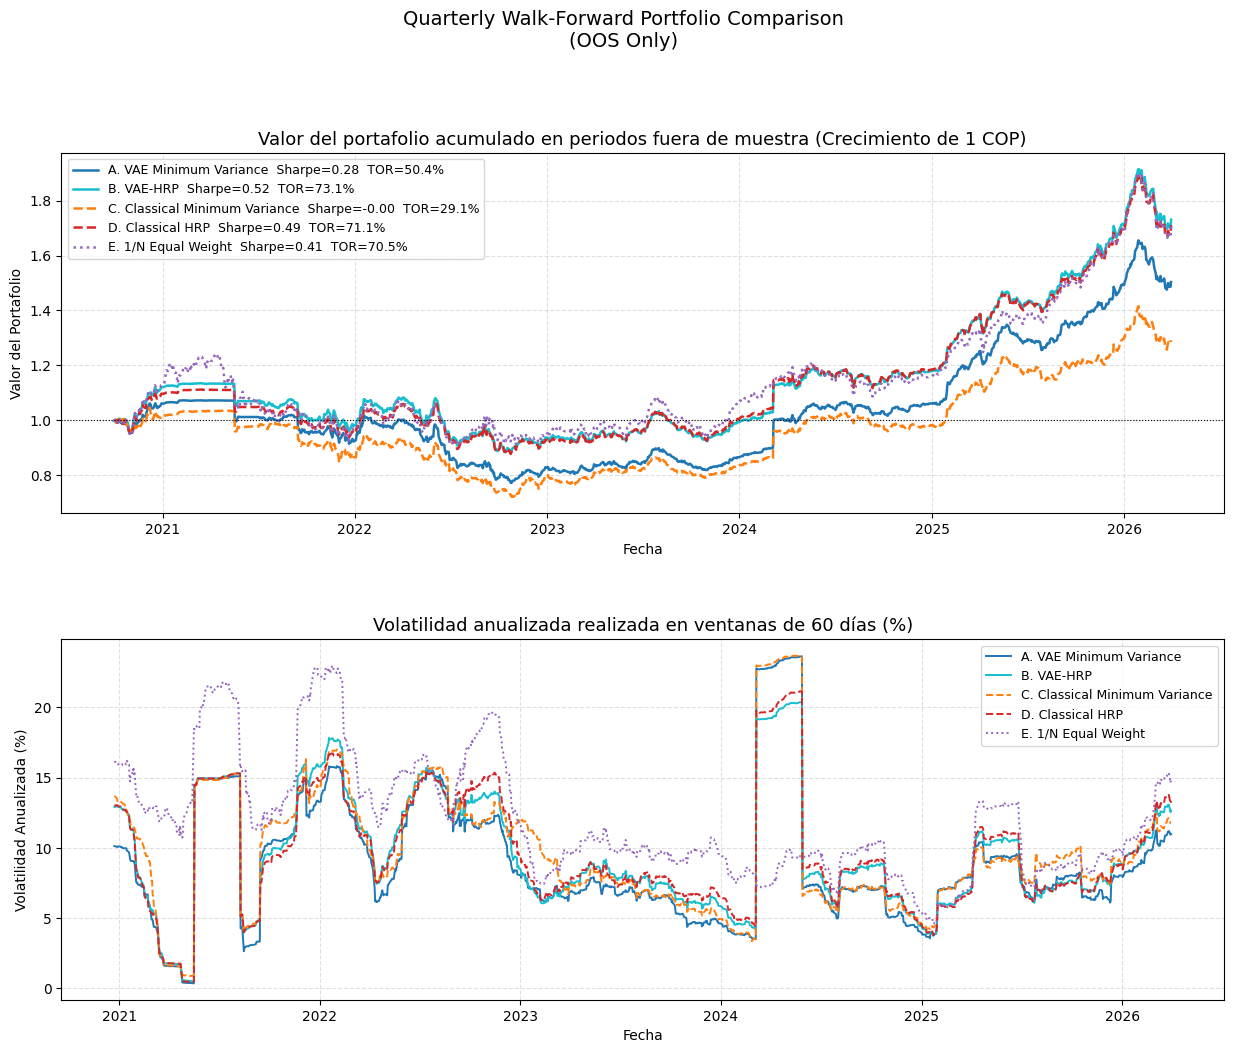

In [19]:
PORTFOLIO_META = {
    'A. VAE Minimum Variance'      : (oos_dae_only, '#1f77b4', '-',  'DAE Covariance Minimum Variance'),
    'B. VAE-HRP'                   : (oos_dae_hrp,  '#17becf', '-',  'HRP — DAE Covariance'),
    'C. Classical Minimum Variance': (oos_mvp_emp,  '#ff7f0e', '--', 'Minimum Variance — Empirical Cov'),
    'D. Classical HRP'             : (oos_hrp_emp,  '#d62728', '--', 'HRP — Empirical Covariance'),
    'E. 1/N Equal Weight'          : (oos_eq_weight,'#9467bd', ':',  '1/N'),
}

fig, axes = plt.subplots(2, 1, figsize=(15, 11), gridspec_kw={'hspace': 0.35})

ax = axes[0]
for label, (ret, color, ls, desc) in PORTFOLIO_META.items():
    cum = (1 + ret).cumprod()
    sr_ = compute_sr(ret)
    tor = compute_total_return(ret)
    ax.plot(cum.index, cum.values, color=color, linestyle=ls, linewidth=1.8,
            label=f'{label}  Sharpe={sr_:.2f}  TOR={tor*100:.1f}%')

ax.set_title('Valor del portafolio acumulado en periodos fuera de muestra (Crecimiento de 1 COP)', fontsize=13)
ax.set_ylabel('Valor del Portafolio')
ax.set_xlabel('Fecha')
ax.legend(fontsize=9, loc='upper left')
ax.grid(linestyle='--', alpha=0.4)
ax.axhline(1.0, color='black', linewidth=0.8, linestyle=':')

ax2 = axes[1]
for label, (ret, color, ls, desc) in PORTFOLIO_META.items():
    rv = ret.rolling(60).std() * np.sqrt(TRADING_DAYS)
    ax2.plot(rv.index, rv.values * 100, color=color, linestyle=ls,
             linewidth=1.4, label=label)

ax2.set_title('Volatilidad anualizada realizada en ventanas de 60 días (%)', fontsize=13)
ax2.set_ylabel('Volatilidad Anualizada (%)')
ax2.set_xlabel('Fecha')
ax2.legend(fontsize=9, loc='upper right')
ax2.grid(linestyle='--', alpha=0.4)

plt.suptitle('Quarterly Walk-Forward Portfolio Comparison\n(OOS Only)',
             fontsize=14, y=1.01)
plt.savefig('equity_curves.png', dpi=150, bbox_inches='tight')
plt.show()


## 14. Tabla Resumen de Métricas de Desempeño

Se consolidan las seis métricas operacionales para los cinco portafolios en un DataFrame formateado. El estilo resalta en verde el mejor valor por métrica:
- **Mínimo destacado:** SD anualizada, Máximo Drawdown y Turnover (menor es mejor).
- **Máximo destacado:** Sharpe Ratio, Retorno Total y ENA (mayor es mejor).

In [20]:
portfolio_data = [
    ('A. VAE Minimum Variance',       oos_dae_only,  records['dae_only']['weights']),
    ('B. VAE-HRP',                    oos_dae_hrp,   records['dae_hrp' ]['weights']),
    ('C. Classical Minimum Variance', oos_mvp_emp,   records['mvp_emp' ]['weights']),
    ('D. Classical HRP',              oos_hrp_emp,   records['hrp_emp' ]['weights']),
    ('E. 1/N Equal Weight',           oos_eq_weight, records['eq_weight']['weights']),
]
 
metric_rows = [summarise_portfolio(label, ret, wlist)
               for label, ret, wlist in portfolio_data]
 
# ── Add ENA to each row ───────────────────────────────────────────────────
for row, (_, _, wlist) in zip(metric_rows, portfolio_data):
    row['ENA'] = compute_ena(wlist)
 
metrics_df = pd.DataFrame(metric_rows).set_index('Portfolio')
 
display_df = metrics_df.copy()
display_df.columns = ['SD (Ann.)', 'Sharpe Ratio (Ann.)', 'Total Return',
                      'Max Drawdown', 'Mean Turnover', 'ENA']
 
print('=' * 90)
print('PORTFOLIO PERFORMANCE METRICS — FULL OUT-OF-SAMPLE PERIOD')
print('=' * 90)
display(display_df.style
        .format('{:.4f}')
        .highlight_min(subset=['SD (Ann.)', 'Max Drawdown', 'Mean Turnover'],
                       color='#c8f7c5')
        .highlight_max(subset=['Sharpe Ratio (Ann.)', 'Total Return', 'ENA'],
                       color='#c8f7c5')
        .set_caption('Green = best value per metric'))


PORTFOLIO PERFORMANCE METRICS — FULL OUT-OF-SAMPLE PERIOD


,SD (Ann.),Sharpe Ratio (Ann.),Total Return,Max Drawdown,Mean Turnover,ENA
Portfolio,,,,,,
A. VAE Minimum Variance,0.1011,0.2781,0.5036,-0.2800,0.4903,9.2947
B. VAE-HRP,0.1056,0.5210,0.7312,-0.2232,0.4139,19.6479
C. Classical Minimum Variance,0.1084,-0.0026,0.2910,-0.3102,0.9460,6.1249
D. Classical HRP,0.1068,0.4938,0.7107,-0.2116,0.4823,21.6888
E. 1/N Equal Weight,0.1281,0.4070,0.7054,-0.2676,0.0000,53.0000


## 15. Desglose por Trimestre

Se presenta la desviación estándar anualizada OOS (en porcentaje) y la pérdida de validación del VAE para **cada trimestre** del walk-forward, permitiendo identificar períodos de alta volatilidad o degradación del modelo. Esto es útil para auditar la estabilidad del framework a lo largo de diferentes regímenes de mercado (por ejemplo, la crisis del COVID-19 en 2020, la recuperación post-pandemia y el régimen reciente de mercados emergentes).

In [21]:
fold_df = pd.DataFrame(fold_summaries).set_index('quarter')
fold_df.columns = ['SD Classical Minimum Variance', 'SD Classical HRP',
                   'SD DAE Minimum Variance', 'SD DAE-HRP',
                   'SD 1/N Equal Weight', 'Best Val Loss']
 
for col in ['SD Classical Minimum Variance', 'SD Classical HRP',
            'SD DAE Minimum Variance', 'SD DAE-HRP', 'SD 1/N Equal Weight']:
    fold_df[col] = (fold_df[col] * 100).round(2)
 
print('Per-Quarter OOS Annualised SD (%) and DAE Validation Loss')
display(fold_df)

Per-Quarter OOS Annualised SD (%) and DAE Validation Loss


,SD Classical Minimum Variance,SD Classical HRP,SD DAE Minimum Variance,SD DAE-HRP,SD 1/N Equal Weight,Best Val Loss
quarter,,,,,,
2020-10-01,13.10,12.49,9.74,12.42,15.45,0.518547
2021-01-01,1.60,1.76,1.56,1.73,12.54,0.558371
2021-04-01,14.24,14.34,14.34,14.33,20.67,0.581057
2021-07-01,11.30,8.74,9.83,9.27,12.09,0.523507
2021-10-01,14.02,14.40,12.87,15.36,22.02,0.521130
2022-01-01,10.80,10.65,9.99,10.85,13.74,0.563745
2022-04-01,14.88,14.28,14.37,14.77,15.74,0.548139
2022-07-01,12.12,13.64,11.60,12.81,16.58,0.590751
2022-10-01,11.60,10.28,8.20,9.15,12.28,0.621050


## 16. Diagnósticos Adicionales: Rutas de Drawdown y Pesos Medios

**Panel izquierdo — Rutas de Drawdown:** Muestra la evolución de la pérdida acumulada desde el pico para cada portafolio a lo largo del período OOS. El área sombreada bajo cada curva facilita la comparación visual de la exposición a drawdowns prolongados.

**Panel derecho — Pesos Medios por Activo:** Gráfico de barras agrupadas que muestra el peso promedio asignado a cada activo del universo, promediado sobre todos los rebalanceos trimestrales. Permite comparar la concentración y distribución del capital entre las cinco estrategias, y verificar si el VAE genera asignaciones sistemáticamente distintas a las empíricas.

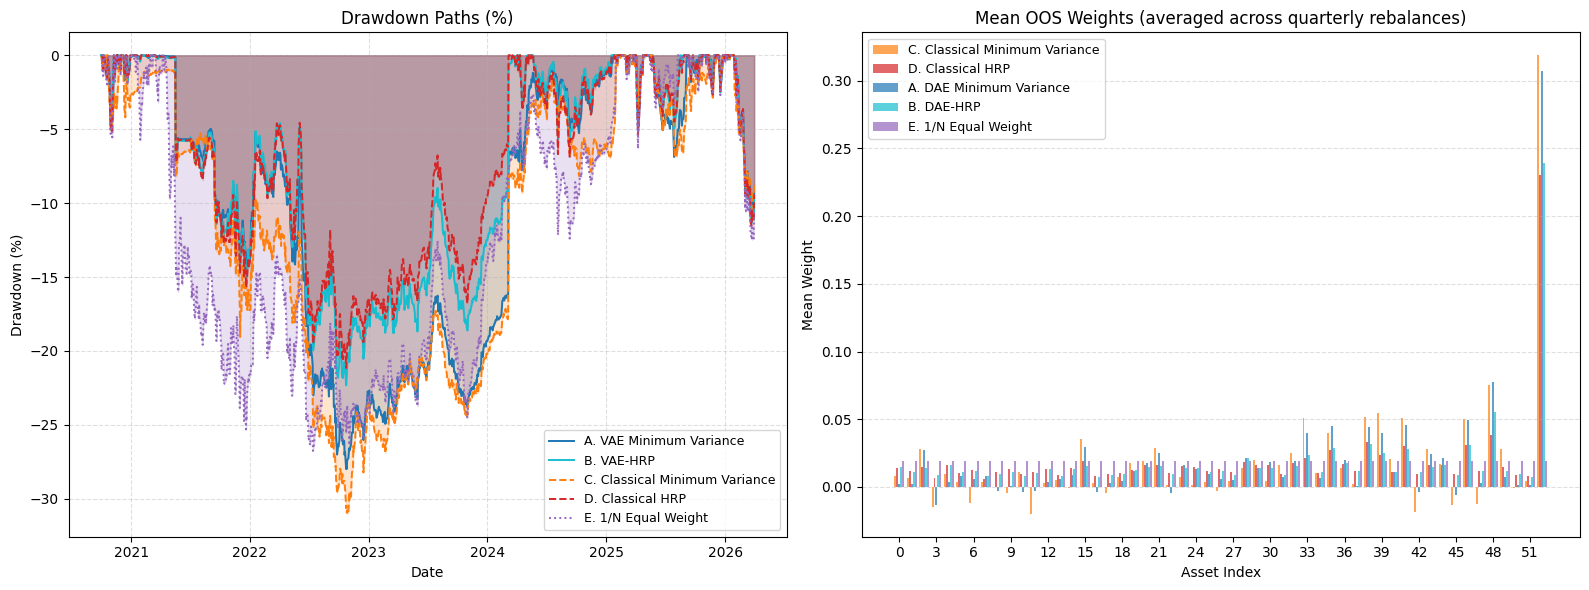

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

ax = axes[0]
for label, (ret, color, ls, desc) in PORTFOLIO_META.items():
    cum  = (1 + ret).cumprod()
    peak = cum.cummax()
    dd   = (cum - peak) / peak
    ax.fill_between(dd.index, dd.values * 100, 0, alpha=0.2, color=color)
    ax.plot(dd.index, dd.values * 100, color=color, linestyle=ls,
            linewidth=1.4, label=label)
ax.set_title('Drawdown Paths (%)', fontsize=12)
ax.set_ylabel('Drawdown (%)')
ax.set_xlabel('Date')
ax.legend(fontsize=9)
ax.grid(linestyle='--', alpha=0.4)

ax2 = axes[1]
n_assets_total = len(returns_df.columns)

def mean_weights(key):
    return np.array(records[key]['weights']).mean(axis=0)

w_avg_mv  = mean_weights('mvp_emp')
w_avg_hrp_emp = mean_weights('hrp_emp')
w_avg_dae = mean_weights('dae_only')
w_avg_hrp = mean_weights('dae_hrp')
w_avg_eq  = mean_weights('eq_weight')

x    = np.arange(n_assets_total)
width = 0.16
ax2.bar(x - 2*width, w_avg_mv,      width, label='C. Classical Minimum Variance', color='#ff7f0e', alpha=0.7)
ax2.bar(x - width,   w_avg_hrp_emp, width, label='D. Classical HRP',              color='#d62728', alpha=0.7)
ax2.bar(x,           w_avg_dae,     width, label='A. DAE Minimum Variance',       color='#1f77b4', alpha=0.7)
ax2.bar(x + width,   w_avg_hrp,     width, label='B. DAE-HRP',                    color='#17becf', alpha=0.7)
ax2.bar(x + 2*width, w_avg_eq,      width, label='E. 1/N Equal Weight',           color='#9467bd', alpha=0.7)
ax2.set_title('Mean OOS Weights (averaged across quarterly rebalances)', fontsize=12)
ax2.set_ylabel('Mean Weight')
ax2.set_xlabel('Asset Index')
ax2.set_xticks(x[::max(1, n_assets_total // 15)])
ax2.legend(fontsize=9)
ax2.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.savefig('diagnostics.png', dpi=150, bbox_inches='tight')
plt.show()


## 17. Scorecard Final

Impresión tabulada de las seis métricas para los cinco portafolios con formato alineado. Sirve como resumen ejecutivo del experimento, consolidando en una sola vista los resultados cuantitativos del período OOS completo para facilitar la comparación directa entre estrategias.

In [23]:
print('\n' + '═' * 92)
print('QUARTERLY WALK-FORWARD — FINAL SCORECARD')
print('═' * 92)
print(f'  {"Portfolio":<32} {"SD":>8} {"Sharpe":>8} {"TOR":>8} {"MD":>8} {"Turnover":>10} {"ENA":>7}')
print('  ' + '-' * 92)
for _, row in metrics_df.iterrows():
    print(f'  {row.name:<32} {row["SD"]:>8.4f}  {row["SR"]:>8.4f}  '
          f'{row["TOR"]:>8.4f}  {row["MD"]:>8.4f}  {row["Turnover"]:>9.4f}  {row["ENA"]:>6.2f}')
print('═' * 92)
print()
print('SD       = Annualised Portfolio Standard Deviation')
print('Sharpe   = Sharpe Ratio  (Ann. Return / Ann. SD, rf=0)')
print('TOR      = Total Cumulative Return over OOS period')
print('MD       = Maximum Drawdown')
print('Turnover = Mean absolute weight change per quarterly rebalance')
print('ENA      = Effective Number of Assets  (= 1 / Σwᵢ²), averaged across rebalances')
 
metrics_df


════════════════════════════════════════════════════════════════════════════════════════════
QUARTERLY WALK-FORWARD — FINAL SCORECARD
════════════════════════════════════════════════════════════════════════════════════════════
  Portfolio                              SD   Sharpe      TOR       MD   Turnover     ENA
  --------------------------------------------------------------------------------------------
  A. VAE Minimum Variance            0.1011    0.2781    0.5036   -0.2800     0.4903    9.29
  B. VAE-HRP                         0.1056    0.5210    0.7312   -0.2232     0.4139   19.65
  C. Classical Minimum Variance      0.1084   -0.0026    0.2910   -0.3102     0.9460    6.12
  D. Classical HRP                   0.1068    0.4938    0.7107   -0.2116     0.4823   21.69
  E. 1/N Equal Weight                0.1281    0.4070    0.7054   -0.2676     0.0000   53.00
════════════════════════════════════════════════════════════════════════════════════════════

SD       = Annualised Portfo

,SD,SR,TOR,MD,Turnover,ENA
Portfolio,,,,,,
A. VAE Minimum Variance,0.101081,0.278067,0.503613,-0.279956,0.490339,9.294670
B. VAE-HRP,0.105645,0.521031,0.731164,-0.223201,0.413949,19.647866
C. Classical Minimum Variance,0.108434,-0.002636,0.291046,-0.310174,0.945990,6.124860
D. Classical HRP,0.106813,0.493803,0.710691,-0.211571,0.482298,21.688771
E. 1/N Equal Weight,0.128116,0.407039,0.705416,-0.267643,0.000000,53.000000
